
## 1. Import Required Libraries

In this section, we import the required Python libraries.

- Pandas: For data manipulation.
- NumPy: For numerical operations.
- Matplotlib: For data visualization.
- Seaborn: For statistical visualization.


In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




## 2. Load Dataset

Load the food delivery dataset using Pandas.

The dataset contains information about food orders, delivery partners, traffic, weather, and delivery time.


In [60]:
df = pd.read_csv("../dataset/foodtimedataset.csv")

df.head()

,ID,Delivery Person ID,Delivery Person Age,Delivery Person Ratings,Restaurant Latitude,Restaurant Longitude,Delivery Location Latitude,Delivery Location Longitude,Order Type,Vehicle Type,Temperature,Humidity,Precipitation,Weather Description,Traffic Level,Distance,Delivery Time
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,NaN,21.66666667
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.26666667
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.58333333
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.18333333
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.45



## 3. Dataset Overview

In this section, we examine the basic structure of the dataset.

We check:
- Number of rows and columns.
- Column names.
- Data types.
- Statistical summary.


In [61]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (10001, 17)

Column Names:
Index(['ID', 'Delivery Person ID', 'Delivery Person Age',
       'Delivery Person Ratings', 'Restaurant Latitude',
       'Restaurant Longitude', 'Delivery Location Latitude',
       'Delivery Location Longitude', 'Order Type', 'Vehicle Type',
       'Temperature', 'Humidity', 'Precipitation', 'Weather Description',
       'Traffic Level', 'Distance', 'Delivery Time'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10001 entries, 0 to 10000
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           10000 non-null  object 
 1   Delivery Person ID           10000 non-null  object 
 2   Delivery Person Age          10000 non-null  float64
 3   Delivery Person Ratings      10000 non-null  float64
 4   Restaurant Latitude          10000 non-null  float64
 5   Restaurant Longitude  

,Delivery Person Age,Delivery Person Ratings,Restaurant Latitude,Restaurant Longitude,Delivery Location Latitude,Delivery Location Longitude,Temperature,Humidity,Precipitation,Distance
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9995.000000,9995.000000,9995.000000,9080.000000
mean,29.522000,4.629370,16.893418,70.177749,17.412655,70.880072,22.936907,66.164882,0.016233,14.292747
std,5.700348,0.322941,8.330948,23.203352,7.336846,21.174585,3.379448,15.602939,0.074911,8.376254
min,15.000000,1.000000,-30.902872,-88.352885,0.010000,0.010000,6.770000,27.000000,0.000000,1.550000
25%,25.000000,4.500000,12.913041,73.170937,12.983959,73.753278,20.140000,54.000000,0.000000,7.620000
50%,29.000000,4.700000,18.546258,75.902847,18.626216,76.022574,23.000000,67.000000,0.000000,13.400000
75%,34.000000,4.800000,22.727021,78.047717,22.785089,78.128092,25.980000,81.000000,0.000000,19.610000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,29.050000,94.000000,1.460000,59.840000



## 4. Missing Values Analysis

Missing values are empty or unavailable values in a dataset.

We identify missing values in each column to understand the quality of our dataset.


ID                               1
Delivery Person ID               1
Delivery Person Age              1
Delivery Person Ratings          1
Restaurant Latitude              1
Restaurant Longitude             1
Delivery Location Latitude       1
Delivery Location Longitude      1
Order Type                       1
Vehicle Type                     1
Temperature                      6
Humidity                         6
Precipitation                    6
Weather Description              6
Traffic Level                  916
Distance                       921
Delivery Time                  542
dtype: int64


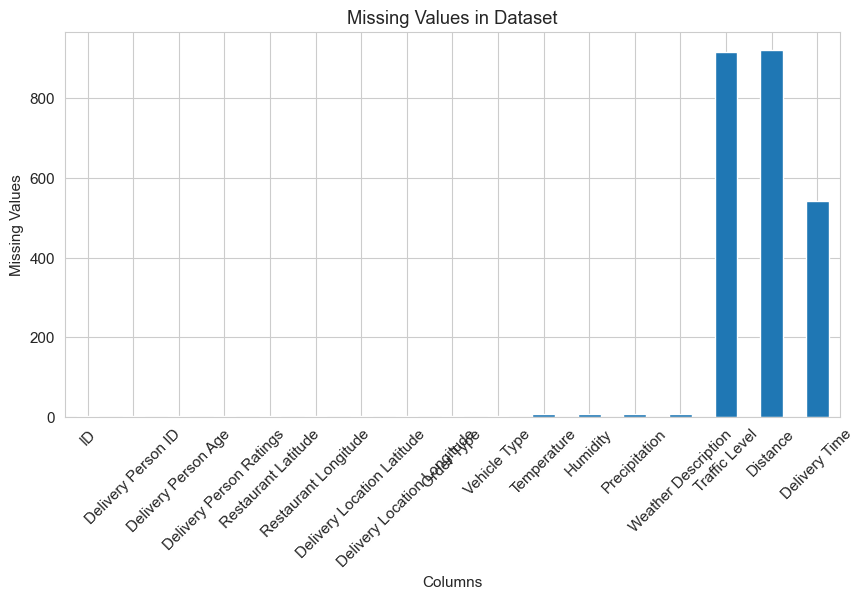

In [62]:
print(df.isnull().sum())

plt.figure(figsize=(10, 5))
df.isnull().sum().plot(kind="bar")

plt.title("Missing Values in Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)

plt.show()


## 5. Delivery Time Distribution

In this section, we analyze the distribution of delivery time.

A histogram helps us understand how frequently different delivery times occur.


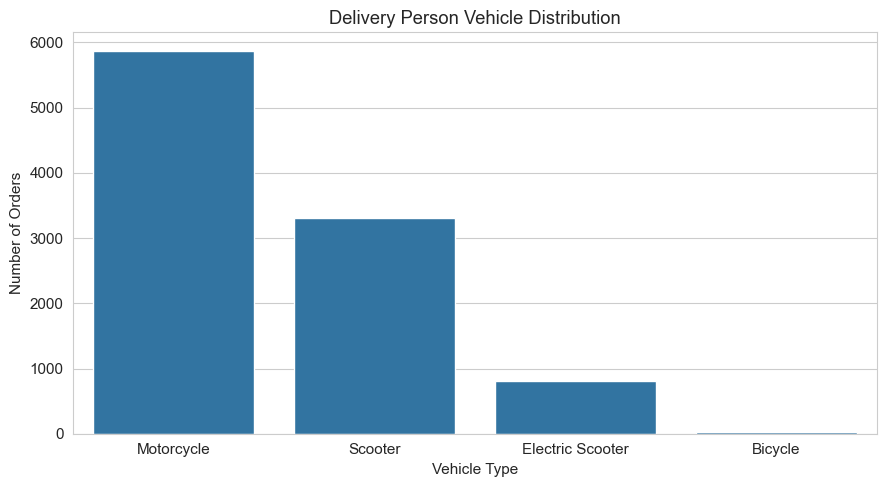

In [63]:
df["Vehicle Type"] = df["Vehicle Type"].str.strip().str.title()

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Vehicle Type",
    order=df["Vehicle Type"].value_counts().index
)

plt.title("Delivery Person Vehicle Distribution")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()


## 6. Delivery Time Outlier Analysis

A boxplot helps identify outliers in delivery time.

Outliers are values that are significantly different from most observations.


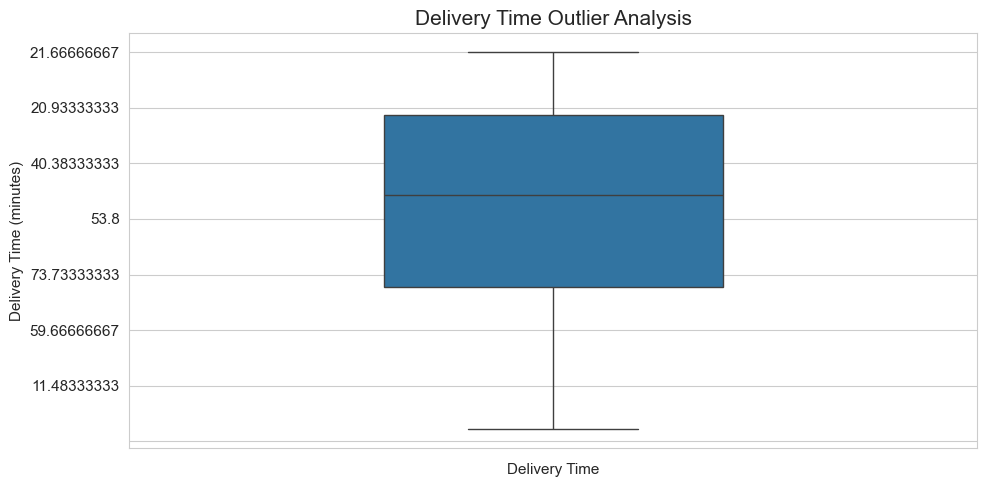

In [64]:
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    y="Delivery Time",
    width=0.4,
    showfliers=True
)

plt.title("Delivery Time Outlier Analysis", fontsize=15)
plt.xlabel("Delivery Time")
plt.ylabel("Delivery Time (minutes)")

plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()


## 7. Traffic Level Analysis

Traffic conditions can affect food delivery time.

We analyze the number of orders under different traffic conditions.


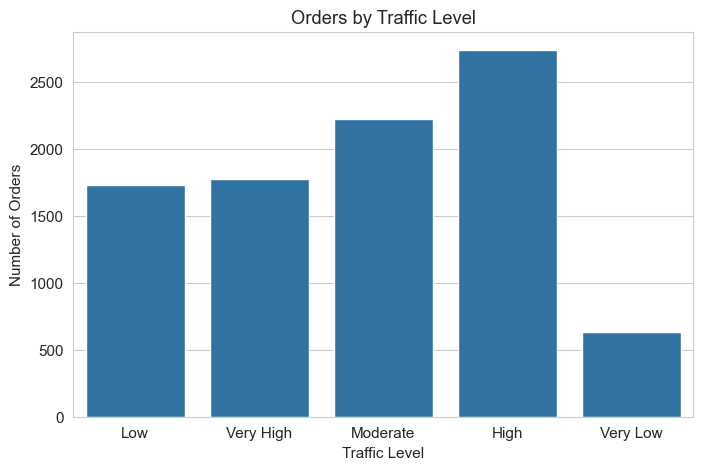

In [65]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Traffic Level")

plt.title("Orders by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Number of Orders")

plt.show()


## 8. Weather Analysis

Weather conditions such as rain, fog, and clear weather may influence delivery operations.

We visualize the number of orders under different weather conditions.


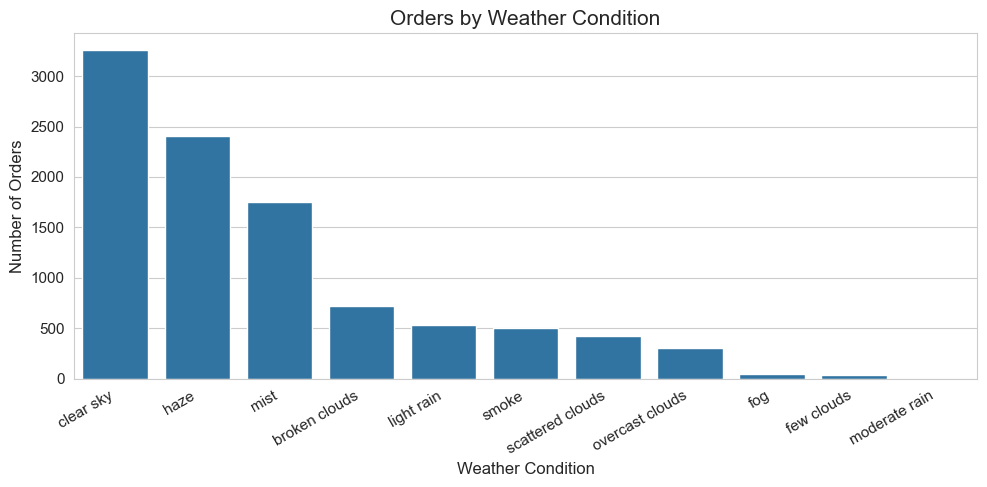

In [66]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Weather Description",
    order=df["Weather Description"].value_counts().index
)

plt.title("Orders by Weather Condition", fontsize=15)
plt.xlabel("Weather Condition", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()


## 9. Distance vs Delivery Time

Delivery distance is an important factor in estimating food delivery time.

A scatter plot helps us understand the relationship between delivery distance and delivery time.


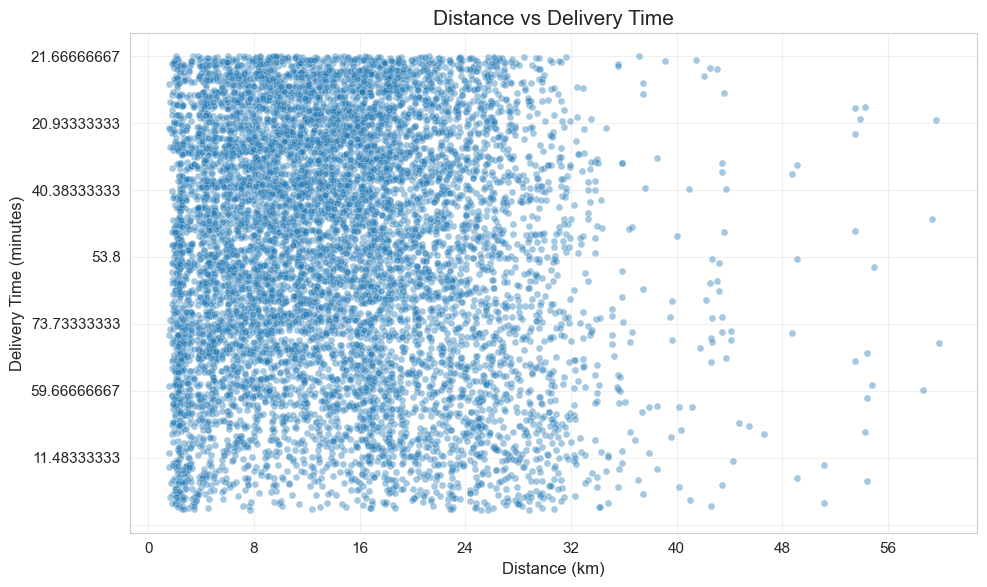

In [67]:
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Distance",
    y="Delivery Time",
    alpha=0.4,
    s=25
)

plt.title("Distance vs Delivery Time", fontsize=15)
plt.xlabel("Distance (km)", fontsize=12)
plt.ylabel("Delivery Time (minutes)", fontsize=12)

plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=10))
plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10 Pie Chart – Orders by Time of Day

This pie chart shows the percentage of orders placed during different times of the day. It helps us understand when most customers place their food orders.

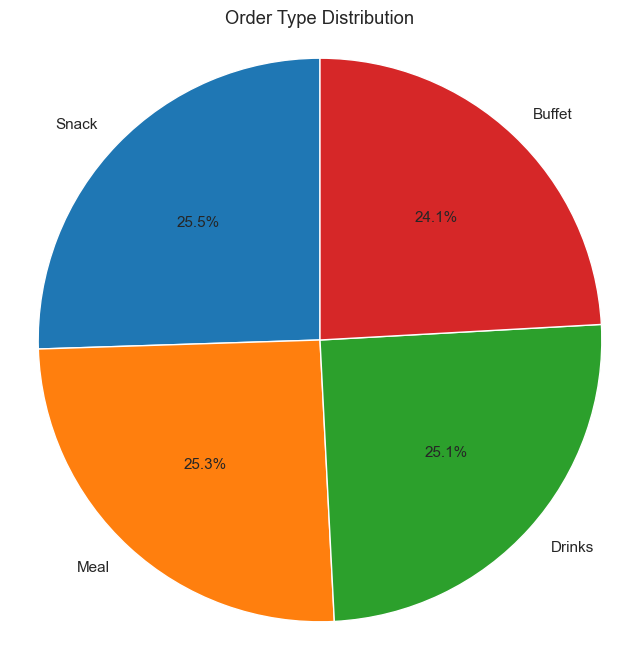

In [68]:
plt.figure(figsize=(8, 8))

order_counts = df["Order Type"].str.strip().value_counts()

plt.pie(
    order_counts,
    labels=order_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Type Distribution")
plt.axis("equal")
plt.show()

## 11. Delivery Person Age Distribution

This histogram shows the age distribution of delivery persons. It helps us understand the age groups of delivery persons in the dataset.

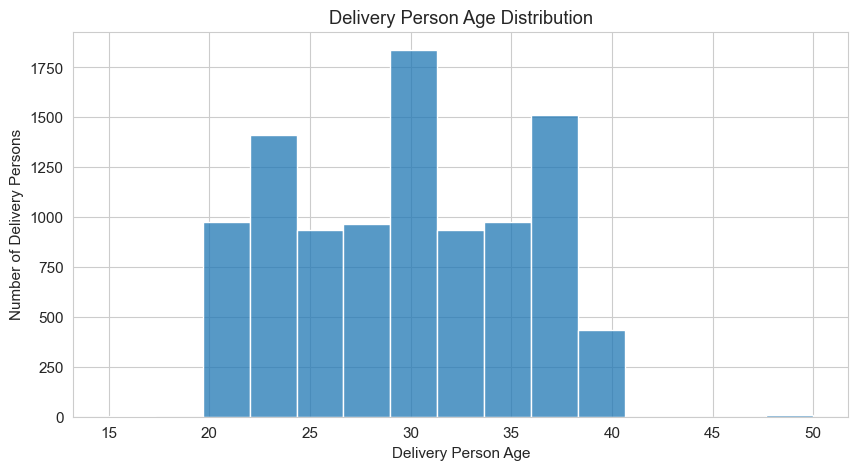

In [69]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Delivery Person Age", bins=15)

plt.title("Delivery Person Age Distribution")
plt.xlabel("Delivery Person Age")
plt.ylabel("Number of Delivery Persons")
plt.show()

## 12. Weather vs Delivery Time

This violin plot shows the distribution of delivery times under different weather conditions. It helps us compare delivery performance during different weather conditions.

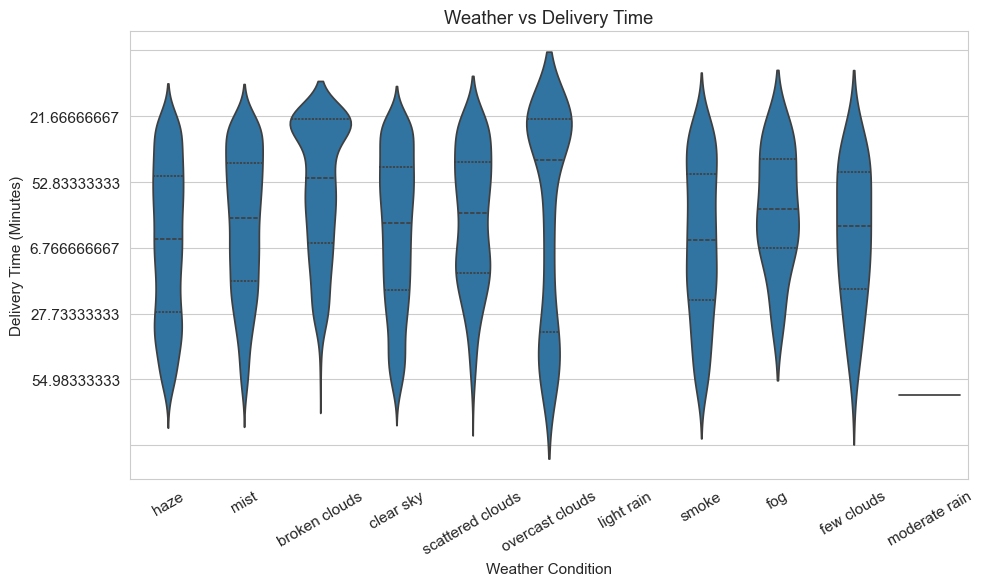

In [70]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="Weather Description",
    y="Delivery Time",
    inner="quartile"
)

plt.title("Weather vs Delivery Time")
plt.xlabel("Weather Condition")
plt.ylabel("Delivery Time (Minutes)")
plt.xticks(rotation=30)
plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))
plt.tight_layout()
plt.show()